<a href="https://colab.research.google.com/github/fatemarampurawalaa-sudo/LLM-practice/blob/main/PyTorch_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch

prices = torch.tensor([1100000, 1450000, 850000])
print(prices)
print(prices.shape)

houses = torch.tensor([[750, 1], [1200, 2], [1050, 2]])
print(houses)
print(houses.shape)

tensor([1100000, 1450000,  850000])
torch.Size([3])
tensor([[ 750,    1],
        [1200,    2],
        [1050,    2]])
torch.Size([3, 2])


In [3]:
area = torch.tensor([750.0, 1200.0, 1050.0])
price = torch.tensor([1100000.0, 1450000.0, 850000.0])

price_per_sqft = price / area
print(price_per_sqft)

print(price.mean())
print(price.max())

tensor([1466.6666, 1208.3334,  809.5238])
tensor(1133333.3750)
tensor(1450000.)


In [4]:
torch.manual_seed(42)

area = torch.randint(600, 2500, (200, 1)).float()
beds = torch.clamp(area // 600, 1, 4)
price = area * 1400 + beds * 50000 + torch.randn(200, 1) * 50000

X = torch.cat([area / 1000, beds], dim=1)
y = price / 1_000_000

print(X.shape, y.shape)
print(X[:3])
print(y[:3])

torch.Size([200, 2]) torch.Size([200, 1])
tensor([[1.2420, 2.0000],
        [1.8670, 3.0000],
        [1.2760, 2.0000]])
tensor([[1.8308],
        [2.7426],
        [1.9336]])


In [5]:
from torch import nn

model = nn.Sequential(
    nn.Linear(2, 8),
    nn.ReLU(),
    nn.Linear(8, 1)
)
print(model)

Sequential(
  (0): Linear(in_features=2, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=1, bias=True)
)


In [6]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(500):
    pred = model(X)              # 1. guess
    loss = loss_fn(pred, y)      # 2. check the mistake
    optimizer.zero_grad()
    loss.backward()              # 3. find who's responsible (backpropagation)
    optimizer.step()             # 4. fix the weights a little

    if epoch % 100 == 0:
        print(f"Epoch {epoch}: loss = {loss.item():.4f}")

print(f"Final loss = {loss.item():.4f}")

Epoch 0: loss = 2.4155
Epoch 100: loss = 0.0345
Epoch 200: loss = 0.0184
Epoch 300: loss = 0.0126
Epoch 400: loss = 0.0086
Final loss = 0.0057


In [7]:
new_flat = torch.tensor([[1200 / 1000, 2.0]])

with torch.no_grad():
    predicted = model(new_flat)

print(f"Predicted price: AED {predicted.item() * 1_000_000:,.0f}")
print(f"Formula price:   AED {1200 * 1400 + 2 * 50000:,.0f}")

Predicted price: AED 1,871,963
Formula price:   AED 1,780,000


In [1]:
!pip install -q transformers datasets accelerate

import torch
print("GPU ready:", torch.cuda.is_available())

GPU ready: True


In [2]:
from datasets import Dataset

reviews = [
    ("Amazing sea view and very spacious apartment", 1),
    ("The landlord fixed everything quickly, great experience", 1),
    ("Beautiful building with a lovely pool and gym", 1),
    ("Very clean, modern kitchen and friendly security", 1),
    ("Perfect location near the metro and supermarket", 1),
    ("The agent was helpful and the viewing was easy", 1),
    ("Quiet neighbourhood, perfect for families", 1),
    ("Great value for money, I renewed my lease happily", 1),
    ("Bright rooms with big windows and a nice balcony", 1),
    ("Parking is easy and maintenance is excellent", 1),
    ("Lovely community with parks and schools nearby", 1),
    ("Best apartment I have rented in Dubai", 1),
    ("The AC broke and nobody came to fix it for weeks", 0),
    ("Very noisy because of construction next door", 0),
    ("The agent never answered my calls", 0),
    ("Dirty building and the lift is always broken", 0),
    ("Rent is too high for such a small apartment", 0),
    ("Water leaks from the ceiling in the bathroom", 0),
    ("The landlord kept my deposit without any reason", 0),
    ("No parking and the area is very crowded", 0),
    ("Cockroaches in the kitchen, terrible experience", 0),
    ("Photos were fake, the flat looked much worse", 0),
    ("Maintenance is slow and very unprofessional", 0),
    ("Worst rental experience, I would not recommend", 0),
]

data = Dataset.from_dict({
    "text": [r[0] for r in reviews],
    "label": [r[1] for r in reviews],
})
data = data.train_test_split(test_size=0.25, seed=42)
print(data)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 18
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 6
    })
})


In [3]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_name = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)

def tokenize(batch):
    return tokenizer(batch["text"], padding="max_length", truncation=True, max_length=32)

data = data.map(tokenize, batched=True)
print(data)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/18 [00:00<?, ? examples/s]

Map:   0%|          | 0/6 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 18
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 6
    })
})


In [4]:
import numpy as np
from transformers import TrainingArguments, Trainer

def accuracy(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {"accuracy": (preds == labels).mean()}

args = TrainingArguments(
    output_dir="review_model",
    num_train_epochs=10,
    per_device_train_batch_size=8,
    learning_rate=5e-5,
    eval_strategy="epoch",
    logging_strategy="epoch",
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=data["train"],
    eval_dataset=data["test"],
    compute_metrics=accuracy,
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,0.692868,0.645982,0.833333
2,0.633273,0.641427,0.833333
3,0.516675,0.608996,0.833333
4,0.410934,0.554319,0.666667
5,0.286055,0.518567,0.833333
6,0.203419,0.493886,0.833333
7,0.153627,0.469943,0.833333
8,0.123283,0.446750,0.833333
9,0.102285,0.429697,0.833333
10,0.088533,0.423005,0.833333


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=30, training_loss=0.32109519640604656, metrics={'train_runtime': 4.7394, 'train_samples_per_second': 37.979, 'train_steps_per_second': 6.33, 'total_flos': 1490258234880.0, 'train_loss': 0.32109519640604656, 'epoch': 10.0})

In [5]:
from transformers import pipeline

classifier = pipeline("text-classification", model=model, tokenizer=tokenizer, device=0)

new_reviews = [
    "The apartment was spotless and the view was stunning",
    "The heater stopped working and the landlord ignored me",
    "Friendly neighbours and a beautiful garden",
    "Too expensive and the walls are very thin",
]

for review in new_reviews:
    result = classifier(review)[0]
    label = "👍 Positive" if result["label"] == "LABEL_1" else "👎 Negative"
    print(f"{label} ({result['score']:.2f}) - {review}")

👍 Positive (0.87) - The apartment was spotless and the view was stunning
👎 Negative (0.86) - The heater stopped working and the landlord ignored me
👍 Positive (0.93) - Friendly neighbours and a beautiful garden
👎 Negative (0.86) - Too expensive and the walls are very thin


In [6]:
from transformers import pipeline

vision = pipeline("zero-shot-image-classification",
                  model="openai/clip-vit-base-patch32", device=0)

room_types = ["kitchen", "bedroom", "bathroom", "living room",
              "swimming pool", "building exterior", "balcony with a view"]

print("Vision model ready ✅")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

... (3 outputs left out)

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

Vision model ready ✅


In [8]:
from google.colab import files
from PIL import Image

uploaded = files.upload()

for name in uploaded:
    image = Image.open(name).convert("RGB")
    results = vision(image, candidate_labels=room_types)
    top = results[0]
    display(image.resize((300, 200)))
    print(f"🏠 {name}: {top['label']} ({top['score']:.0%} sure)\n")

   busy (code 429), retrying in 10s...
   busy (code 429), retrying in 10s...
   busy (code 429), retrying in 10s...


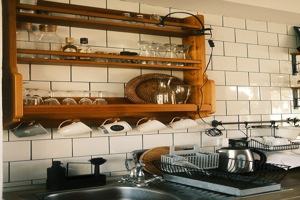

🏠 Photo 'kitchen': AI says kitchen (99% sure)

   busy (code 429), retrying in 10s...
   busy (code 429), retrying in 10s...


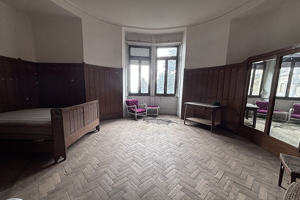

🏠 Photo 'bedroom': AI says bedroom (86% sure)

   busy (code 429), retrying in 10s...


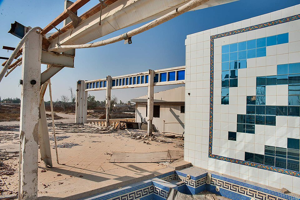

🏠 Photo 'pool': AI says building exterior (80% sure)



In [11]:
import requests, time
from io import BytesIO
from PIL import Image

photos = {
    "kitchen": "https://upload.wikimedia.org/wikipedia/commons/thumb/a/a3/Modern_kitchen_interior_featuring_wooden_shelving_and_organized_dishware_in_a_cozy_setting.jpg/960px-Modern_kitchen_interior_featuring_wooden_shelving_and_organized_dishware_in_a_cozy_setting.jpg",
    "bedroom": "https://upload.wikimedia.org/wikipedia/commons/thumb/1/1d/A_bedroom_of_the_Grand_Hotel_Campo_dei_Fiori.jpg/960px-A_bedroom_of_the_Grand_Hotel_Campo_dei_Fiori.jpg",
    "pool": "https://upload.wikimedia.org/wikipedia/commons/thumb/6/6f/Swimming_pool_in_Al_Mashrab.jpg/960px-Swimming_pool_in_Al_Mashrab.jpg",
}
headers = {"User-Agent": "PropertyVisionDemo/1.0 (learning project; Colab)"}

def get_photo(url):
    for attempt in range(5):
        r = requests.get(url, headers=headers)
        if r.status_code == 200 and r.headers.get("content-type", "").startswith("image"):
            return Image.open(BytesIO(r.content)).convert("RGB")
        print(f"   busy (code {r.status_code}), retrying in 10s...")
        time.sleep(10)
    return None

for name, url in photos.items():
    image = get_photo(url)
    if image is None:
        print(f"❌ Could not get '{name}' photo\n")
        continue
    results = vision(image, candidate_labels=room_types)
    top = results[0]
    display(image.resize((300, 200)))
    print(f"🏠 Photo '{name}': AI says {top['label']} ({top['score']:.0%} sure)\n")

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

[transformers] DetrForObjectDetection LOAD REPORT from: facebook/detr-resnet-50
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
model.backbone.model.layer1.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ chair (100% sure)
✅ chair (93% sure)
✅ chair (98% sure)
✅ bed (91% sure)
✅ bed (86% sure)
✅ couch (95% sure)


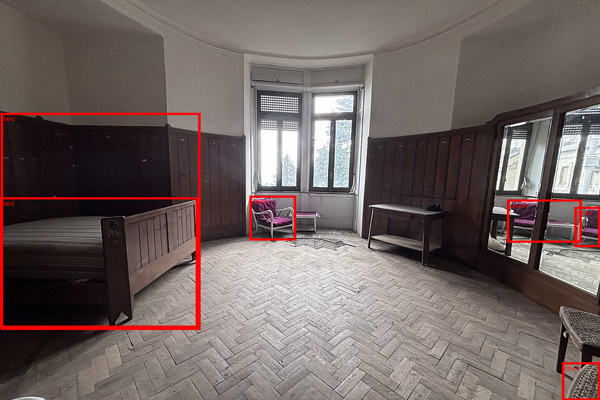

In [13]:
!pip install -q timm
from PIL import ImageDraw

detector = pipeline("object-detection", model="facebook/detr-resnet-50", device=0)

photo = get_photo(photos["bedroom"])
objects = detector(photo)

draw = ImageDraw.Draw(photo)
for obj in objects:
    if obj["score"] > 0.8:
        box = obj["box"]
        draw.rectangle([box["xmin"], box["ymin"], box["xmax"], box["ymax"]], outline="red", width=4)
        draw.text((box["xmin"] + 5, box["ymin"] + 5), obj["label"], fill="red")
        print(f"✅ {obj['label']} ({obj['score']:.0%} sure)")

display(photo.resize((600, 400)))